In [37]:
#1. 加载
import sys
import numpy as np #计算工具
import matplotlib
import matplotlib.pyplot as plt #画图工具

In [38]:
#2. 生成实验数据
import numpy as np
# 第一部分：设置数据规模
n_train = 60
n_val = 500
n_test = 2000
n_features = 120
# 主实验的噪声标准差
noise_std = 1.0
# 开发阶段固定一个随机种子，方便重复检查
rng = np.random.default_rng(12345)
# 第二部分：设置输入特征的标准差
# 第一个特征标准差为5，因此方差为25
# 其余特征标准差为1，因此方差为1
feature_std = np.ones(n_features)
feature_std[0] = 5.0
# 第三部分：分别生成三组独立的输入数据
X_train = rng.normal(
    size=(n_train, n_features)
) * feature_std

X_val = rng.normal(
    size=(n_val, n_features)
) * feature_std

X_test = rng.normal(
    size=(n_test, n_features)
) * feature_std
# 第四部分：确定真实答案
# 真实答案就是每条数据的第一个特征
y_train_true = X_train[:, 0].copy()
y_val_true = X_val[:, 0].copy()
y_test = X_test[:, 0].copy()
# 第五部分：生成训练标签和验证标签中的噪声
train_noise = rng.normal(
    loc=0.0,
    scale=noise_std,
    size=n_train
)

val_noise = rng.normal(
    loc=0.0,
    scale=noise_std,
    size=n_val
)

# 真实答案加噪声，得到训练和验证时使用的标签
y_train = y_train_true + train_noise
y_val = y_val_true + val_noise
# 第六部分：查看数据尺寸
print("训练输入 X_train：", X_train.shape)
print("训练标签 y_train：", y_train.shape)

print("验证输入 X_val：", X_val.shape)
print("验证标签 y_val：", y_val.shape)

print("测试输入 X_test：", X_test.shape)
print("测试答案 y_test：", y_test.shape)
# 第七部分：观察第一条训练数据
print("\n第一条训练数据：")
print("前5个输入数字：", X_train[0, :5])
print("真实答案：", y_train_true[0])
print("添加的噪声：", train_noise[0])
print("最终训练标签：", y_train[0])

print("\n第二步：数据生成完成")

训练输入 X_train： (60, 120)
训练标签 y_train： (60,)
验证输入 X_val： (500, 120)
验证标签 y_val： (500,)
测试输入 X_test： (2000, 120)
测试答案 y_test： (2000,)

第一条训练数据：
前5个输入数字： [-7.11912518  1.26372846 -0.87066174 -0.25917323 -0.07534331]
真实答案： -7.119125182273156
添加的噪声： -1.25302233122684
最终训练标签： -8.372147513499996

第二步：数据生成完成


In [39]:
#3. 训练第一个线性回归模型，并检查它的预测误差
import numpy as np

# 第一部分：训练初始模型
# 求出最小范数最小二乘解
beta_initial = np.linalg.lstsq(
    X_train,
    y_train,
    rcond=None
)[0]

# 第二部分：使用模型进行预测
train_pred_initial = X_train @ beta_initial
val_pred_initial = X_val @ beta_initial

# 第三部分：计算均方误差MSE
mse_train_initial = np.mean(
    (train_pred_initial - y_train) ** 2
)

mse_val_initial = np.mean(
    (val_pred_initial - y_val) ** 2
)

# 第四部分：查看模型和结果
print("模型系数的形状：", beta_initial.shape)
print("训练预测的形状：", train_pred_initial.shape)
print("验证预测的形状：", val_pred_initial.shape)

print("\n初始模型的误差：")
print(f"训练MSE：{mse_train_initial:.6e}")
print(f"验证MSE：{mse_val_initial:.6f}")

print("\n模型学到的前5个系数：")
print(np.round(beta_initial[:5], 4))

print("\n前5个训练标签：")
print(np.round(y_train[:5], 4))

print("对应的前5个训练预测：")
print(np.round(train_pred_initial[:5], 4))

print("\n第三步：初始模型训练完成")

模型系数的形状： (120,)
训练预测的形状： (60,)
验证预测的形状： (500,)

初始模型的误差：
训练MSE：2.118090e-28
验证MSE：1.875483

模型学到的前5个系数：
[0.9763 0.1287 0.0753 0.073  0.022 ]

前5个训练标签：
[-8.3721 -3.8202  4.155   0.4835  0.6792]
对应的前5个训练预测：
[-8.3721 -3.8202  4.155   0.4835  0.6792]

第三步：初始模型训练完成


In [40]:
#4. 实现岭回归，用验证集选择参数，再与初始模型比较
import numpy as np

# 第一部分：固定候选惩罚系数
lambda_candidates = [0.01, 0.1, 1.0, 10.0, 100.0]

# 从实际训练数据中读取样本数和特征数
n_fit, p_fit = X_train.shape

# 准备求解岭回归需要的矩阵
ridge_gram = X_train.T @ X_train
ridge_rhs = X_train.T @ y_train
ridge_identity = np.eye(p_fit)

# 第二部分：准备记录结果
ridge_records = []

best_lambda = None
beta_ridge = None
mse_train_ridge = None
mse_val_ridge = np.inf

print("逐个尝试岭回归参数：")

# 第三部分：训练每个候选模型
for lam in lambda_candidates:

    # 目标函数：
    # 训练MSE + lam * 系数平方和
    # 因此求解时，惩罚项需要使用 n_fit * lam
    beta_current = np.linalg.solve(
        ridge_gram + n_fit * lam * ridge_identity,
        ridge_rhs
    )

    # 在训练集和验证集上进行预测
    train_pred_current = X_train @ beta_current
    val_pred_current = X_val @ beta_current

    # 计算当前模型的误差
    train_mse_current = float(
        np.mean((train_pred_current - y_train) ** 2)
    )

    val_mse_current = float(
        np.mean((val_pred_current - y_val) ** 2)
    )

    # 保存当前候选参数的结果
    ridge_records.append(
        [lam, train_mse_current, val_mse_current]
    )

    print(
        f"lambda={lam:g} | "
        f"训练MSE={train_mse_current:.6f} | "
        f"验证MSE={val_mse_current:.6f}"
    )

    # 只依据验证误差，更新当前最佳模型
    if val_mse_current < mse_val_ridge:
        best_lambda = lam
        beta_ridge = beta_current.copy()
        mse_train_ridge = train_mse_current
        mse_val_ridge = val_mse_current

# 第四部分：显示选中的参数
print("\n验证集选出的lambda：", best_lambda)
print("岭回归系数的形状：", beta_ridge.shape)

# 第五部分：与第三步的初始模型比较
print("\n初始模型：")
print(f"训练MSE：{mse_train_initial:.6e}")
print(f"验证MSE：{mse_val_initial:.6f}")

print("\n验证集选出的岭回归模型：")
print(f"训练MSE：{mse_train_ridge:.6f}")
print(f"验证MSE：{mse_val_ridge:.6f}")

print("\n第四步：岭回归训练与验证选参完成")

逐个尝试岭回归参数：
lambda=0.01 | 训练MSE=0.000142 | 验证MSE=1.846847
lambda=0.1 | 训练MSE=0.009368 | 验证MSE=1.669895
lambda=1 | 训练MSE=0.209014 | 验证MSE=1.354457
lambda=10 | 训练MSE=2.553717 | 验证MSE=3.517402
lambda=100 | 训练MSE=16.558208 | 验证MSE=17.305698

验证集选出的lambda： 1.0
岭回归系数的形状： (120,)

初始模型：
训练MSE：2.118090e-28
验证MSE：1.875483

验证集选出的岭回归模型：
训练MSE：0.209014
验证MSE：1.354457

第四步：岭回归训练与验证选参完成


开始逐轮自蒸馏：
第 0 轮 | 原始训练MSE=2.118090e-28 | 验证MSE=1.875483
第  1 轮 | 原始训练MSE=5.800058e-01 | 验证MSE=1.550932
第  2 轮 | 原始训练MSE=9.773092e-01 | 验证MSE=1.593033
第  3 轮 | 原始训练MSE=1.373107e+00 | 验证MSE=1.599741
第  4 轮 | 原始训练MSE=1.801261e+00 | 验证MSE=1.850726
第  5 轮 | 原始训练MSE=2.413460e+00 | 验证MSE=2.453252
第  6 轮 | 原始训练MSE=2.592501e+00 | 验证MSE=2.793986
第  7 轮 | 原始训练MSE=3.582641e+00 | 验证MSE=3.603600
第  8 轮 | 原始训练MSE=3.754644e+00 | 验证MSE=3.964885
第  9 轮 | 原始训练MSE=4.116000e+00 | 验证MSE=4.237394
第 10 轮 | 原始训练MSE=4.761186e+00 | 验证MSE=4.754009
第 11 轮 | 原始训练MSE=5.044657e+00 | 验证MSE=5.112417
第 12 轮 | 原始训练MSE=5.350170e+00 | 验证MSE=5.344508
第 13 轮 | 原始训练MSE=5.748025e+00 | 验证MSE=5.921773
第 14 轮 | 原始训练MSE=6.123859e+00 | 验证MSE=6.414344
第 15 轮 | 原始训练MSE=6.745953e+00 | 验证MSE=6.997044

已保存的模型数量： 16
第15轮模型系数的形状： (120,)


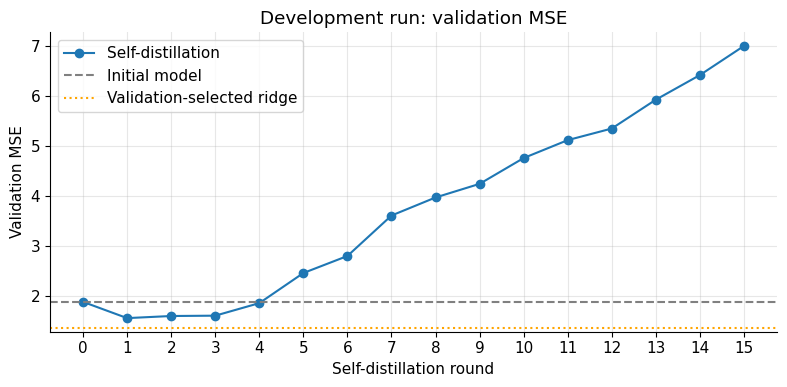


第五步：逐轮自蒸馏完成


In [41]:
#5. 逐轮自蒸馏，观察模型反复学习自己的预测后，误差怎样变化
import numpy as np
import matplotlib.pyplot as plt

# 第一部分：设置自蒸馏轮数
max_rounds = 15

# 为自蒸馏的新输入单独设置开发阶段随机种子
# 每次重新运行这一整格，可以重复检查相同轨迹
rng_distill = np.random.default_rng(54321)

# 第二部分：从第三步的初始模型出发
# 取第三步初始模型的系数，作为第一位“教师”
beta_teacher = beta_initial.copy()

# 保存每一轮的模型系数
distill_betas = [beta_teacher.copy()]

# 保存第0轮在原始训练集和验证集上的误差
distill_train_mses = [
    float(np.mean((X_train @ beta_teacher - y_train) ** 2))
]

distill_val_mses = [
    float(np.mean((X_val @ beta_teacher - y_val) ** 2))
]

print("开始逐轮自蒸馏：")
print(
    f"第 0 轮 | "
    f"原始训练MSE={distill_train_mses[0]:.6e} | "
    f"验证MSE={distill_val_mses[0]:.6f}"
)

# 第三部分：依次训练第1至第15轮模型
for t in range(1, max_rounds + 1):

    # 每轮独立生成一批新输入，保持原来的特征尺度
    X_new = rng_distill.normal(
        size=X_train.shape
    ) * feature_std

    # 上一轮模型生成伪标签，不额外加入噪声
    # 让上一轮模型预测新输入，把预测结果当作下一轮的训练答案
    y_pseudo = X_new @ beta_teacher

    # 使用新输入和伪标签，训练下一轮模型
    beta_student = np.linalg.lstsq(
        X_new,
        y_pseudo,
        rcond=None
    )[0]

    # 在最初的带噪声训练数据上计算误差
    train_mse = float(
        np.mean((X_train @ beta_student - y_train) ** 2)
    )

    # 在固定的独立验证集上计算误差
    val_mse = float(
        np.mean((X_val @ beta_student - y_val) ** 2)
    )

    # 保存这一轮的模型与误差
    distill_betas.append(beta_student.copy())
    distill_train_mses.append(train_mse)
    distill_val_mses.append(val_mse)

    print(
        f"第 {t:2d} 轮 | "
        f"原始训练MSE={train_mse:.6e} | "
        f"验证MSE={val_mse:.6f}"
    )

    # 当前学生成为下一轮的教师
    beta_teacher = beta_student.copy()

# 第四部分：保存第15轮模型
beta_final = distill_betas[-1].copy()

print("\n已保存的模型数量：", len(distill_betas))
print("第15轮模型系数的形状：", beta_final.shape)

# 第五部分：绘制开发阶段的验证误差曲线
plt.figure(figsize=(8, 4))

plt.plot(
    range(max_rounds + 1),
    distill_val_mses,
    marker="o",
    label="Self-distillation"
)

plt.axhline(
    mse_val_initial,
    color="gray",
    linestyle="--",
    label="Initial model"
)

plt.axhline(
    mse_val_ridge,
    color="orange",
    linestyle=":",
    label="Validation-selected ridge"
)

plt.xlabel("Self-distillation round")
plt.ylabel("Validation MSE")
plt.title("Development run: validation MSE")
plt.xticks(range(max_rounds + 1))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\n第五步：逐轮自蒸馏完成")

In [42]:
#6. 让程序自动选择停止轮数，保存早停模型，并汇总四种方法
# 找到验证MSE最小的一轮，把那一轮模型选作自蒸馏的最终输出
import numpy as np

# 第一部分：只根据验证MSE，自动选择停止轮数
best_round = int(np.argmin(distill_val_mses))

# 取出对应轮次已经训练好的模型
beta_early = distill_betas[best_round].copy()

# 第二部分：重新计算早停模型的训练和验证误差
mse_train_early = float(
    np.mean((X_train @ beta_early - y_train) ** 2)
)

mse_val_early = float(
    np.mean((X_val @ beta_early - y_val) ** 2)
)

# 核对：选中的模型是否与第五步保存的误差对应
record_matches = bool(
    np.isclose(
        mse_val_early,
        distill_val_mses[best_round]
    )
)

# 第三部分：取出第15轮模型，并计算误差
beta_final = distill_betas[-1].copy()

mse_train_final = float(
    np.mean((X_train @ beta_final - y_train) ** 2)
)

mse_val_final = float(
    np.mean((X_val @ beta_final - y_val) ** 2)
)

# 第四部分：显示选择结果
print("参与选择的模型数量：", len(distill_val_mses))
print("验证集选出的停止轮数：", best_round)
print("早停模型系数的形状：", beta_early.shape)

print(f"早停模型训练MSE：{mse_train_early:.6f}")
print(f"早停模型验证MSE：{mse_val_early:.6f}")
print("与第五步保存的验证误差一致：", record_matches)

print("\n岭回归选出的lambda：", best_lambda)

# 第五部分：保存四种方法的开发阶段比较结果
development_comparison = [
    ["Initial", mse_train_initial, mse_val_initial],
    ["Ridge", mse_train_ridge, mse_val_ridge],
    [f"EarlyStop(t={best_round})",
     mse_train_early, mse_val_early],
    [f"Final(t={max_rounds})",
     mse_train_final, mse_val_final]
]

print("\n四种方法的开发阶段比较：")

for model_name, train_mse, val_mse in development_comparison:
    print(
        f"{model_name:<20} | "
        f"训练MSE={train_mse:.6e} | "
        f"验证MSE={val_mse:.6f}"
    )

print("\n第六步：验证集早停选择与四种方法汇总完成")

参与选择的模型数量： 16
验证集选出的停止轮数： 1
早停模型系数的形状： (120,)
早停模型训练MSE：0.580006
早停模型验证MSE：1.550932
与第五步保存的验证误差一致： True

岭回归选出的lambda： 1.0

四种方法的开发阶段比较：
Initial              | 训练MSE=2.118090e-28 | 验证MSE=1.875483
Ridge                | 训练MSE=2.090144e-01 | 验证MSE=1.354457
EarlyStop(t=1)       | 训练MSE=5.800058e-01 | 验证MSE=1.550932
Final(t=15)          | 训练MSE=6.745953e+00 | 验证MSE=6.997044

第六步：验证集早停选择与四种方法汇总完成


In [43]:
#7. 检查关键逻辑，固定正式实验配置
# 1. 检查数据规模、特征尺度和模型记录是否符合约定。
# 2. 做一个有明确数学预期的检查，确认最小范数自蒸馏的行为。
# 3. 保存正式实验参数，下一步按这些参数运行。
# 4.这里的“固定配置”，意思是：先把实验设置记录清楚，再进行正式测试评价。

import numpy as np
import matplotlib
import platform
import json
from pathlib import Path

# 开始检查前，先把状态设为未通过
formal_checks_passed = False

# 定义一个小工具：检查失败就停止，成功就打印提示
def check_condition(condition, message):
    if not condition:
        raise ValueError("检查未通过：" + message)
    print("通过：" + message)


# 第一部分：检查数据尺寸
check_condition(
    X_train.shape == (60, 120)
    and X_val.shape == (500, 120)
    and X_test.shape == (2000, 120),
    "训练、验证、测试输入尺寸正确"
)

check_condition(
    y_train.shape == (60,)
    and y_val.shape == (500,)
    and y_test.shape == (2000,),
    "三组答案的数量正确"
)

data_arrays = [
    X_train, y_train,
    X_val, y_val,
    X_test, y_test
]

check_condition(
    all(np.isfinite(a).all() for a in data_arrays),
    "数据中没有NaN或无穷大"
)


# 第二部分：检查特征尺度
check_condition(
    len(feature_std) == 120
    and feature_std[0] == 5.0
    and np.all(feature_std[1:] == 1.0),
    "第一个特征标准差为5，其余为1"
)


# 第三部分：检查自蒸馏记录
check_condition(
    max_rounds == 15
    and len(distill_betas) == 16
    and len(distill_train_mses) == 16
    and len(distill_val_mses) == 16,
    "第0至15轮的模型和误差记录齐全"
)

# 根据保存的每一轮模型，重新计算验证误差
recomputed_val_mses = []

for beta in distill_betas:
    value = float(
        np.mean((X_val @ beta - y_val) ** 2)
    )
    recomputed_val_mses.append(value)

check_condition(
    np.allclose(
        recomputed_val_mses,
        distill_val_mses,
        rtol=1e-10,
        atol=1e-12
    ),
    "每轮模型与保存的验证误差对应一致"
)


# 第四部分：检查“复用同一批输入”的数学性质
# 这是实现检查，不是正式比较中的第五种方法
beta_reuse = np.linalg.lstsq(
    X_train,
    X_train @ beta_initial,
    rcond=None
)[0]

relative_change = float(
    np.linalg.norm(beta_reuse - beta_initial)
    / max(np.linalg.norm(beta_initial), 1e-12)
)

check_condition(
    relative_change < 1e-10,
    "复用同一批输入时，最小范数模型基本不变"
)

print(f"\n复用输入时的系数相对变化：{relative_change:.6e}")


# 第五部分：固定正式实验配置
formal_config = {
    "n_train": 60,
    "n_features": 120,
    "n_val": 500,
    "n_test": 2000,

    "spike_variance": 25.0,
    "true_beta": "e1",
    "fit_intercept": False,
    "standardize_features": False,

    "max_rounds": 15,
    "noise_stds": [0.5, 1.0, 2.0],
    "seeds": list(range(10)),

    "ridge_lambdas": [0.01, 0.1, 1.0, 10.0, 100.0],
    "ridge_objective": "training_MSE + lambda * squared_L2_norm",

    "selection_metric": "validation_MSE",
    "early_stop_tie_rule": "earliest_round",
    "ridge_tie_rule": "smallest_lambda",

    "validation_labels": "noisy",
    "test_targets": "noiseless_signal",

    "rng_scheme": "SeedSequence([seed, noise_code]).spawn(4)",
    "noise_code_rule": "int(round(1000 * noise_std))",
    "rng_stream_order": [
        "train", "validation", "distillation", "test"
    ],

    "environment": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__
    }
}


# 第六部分：保存配置文件
output_dir = Path("project_outputs")
output_dir.mkdir(exist_ok=True)

config_path = output_dir / "formal_config.json"

config_path.write_text(
    json.dumps(
        formal_config,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

formal_checks_passed = True

n_trials = (
    len(formal_config["noise_stds"])
    * len(formal_config["seeds"])
)

print("\n正式实验配置已记录：")
print("噪声条件：", formal_config["noise_stds"])
print("随机种子：", formal_config["seeds"])
print("正式实验次数：", n_trials)
print("预计四种方法比较记录数：", n_trials * 4)
print(
    "预计逐轮记录数：",
    n_trials * (formal_config["max_rounds"] + 1)
)
print("配置文件位置：", config_path)
print("运行环境：", formal_config["environment"])

print("\n第七步：关键检查通过，正式配置已保存")

通过：训练、验证、测试输入尺寸正确
通过：三组答案的数量正确
通过：数据中没有NaN或无穷大
通过：第一个特征标准差为5，其余为1
通过：第0至15轮的模型和误差记录齐全
通过：每轮模型与保存的验证误差对应一致
通过：复用同一批输入时，最小范数模型基本不变

复用输入时的系数相对变化：3.764554e-15

正式实验配置已记录：
噪声条件： [0.5, 1.0, 2.0]
随机种子： [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
正式实验次数： 30
预计四种方法比较记录数： 120
预计逐轮记录数： 480
配置文件位置： project_outputs/formal_config.json
运行环境： {'python': '3.13.18', 'numpy': '2.4.6', 'matplotlib': '3.10.0'}

第七步：关键检查通过，正式配置已保存


In [44]:
#8A. 正式实验
# 3种噪声：`0.5、1.0、2.0`。
# 每种噪声运行10个随机种子，共 30次独立实验。
# 每次比较：初始模型、岭回归、验证集早停、蒸馏到第15轮。
# 每次都重新生成数据、选择岭回归参数和停止轮数，不沿用开发实验中的 λ=1、停止轮数=1。
# 参数选定后，再用独立测试集评价。

import numpy as np
import csv
import json
import time
import hashlib
import shutil
from pathlib import Path


def formal_mse(y_true, y_pred):
    if y_true.shape != y_pred.shape:
        raise ValueError("预测与答案形状不一致")

    value = float(np.mean((y_pred - y_true) ** 2))

    if not np.isfinite(value):
        raise ValueError("误差出现无效数值")

    return value


def run_formal_trial(cfg, sigma, seed):
    n = cfg["n_train"]
    p = cfg["n_features"]
    total_rounds = cfg["max_rounds"]

    # 为训练、验证、蒸馏、测试分别建立随机数流
    noise_code = int(round(1000 * sigma))
    children = np.random.SeedSequence(
        [int(seed), noise_code]
    ).spawn(4)

    rng_train, rng_val, rng_distill, rng_test = [
        np.random.default_rng(s) for s in children
    ]

    scales = np.ones(p)
    scales[0] = np.sqrt(cfg["spike_variance"])

    # 1. 生成初始训练数据和独立验证数据
    X0 = rng_train.normal(size=(n, p)) * scales
    y0 = X0[:, 0] + rng_train.normal(scale=sigma, size=n)

    Xv = rng_val.normal(size=(cfg["n_val"], p)) * scales
    yv = Xv[:, 0] + rng_val.normal(
        scale=sigma, size=cfg["n_val"]
    )

    trial_id = {
        "noise_std": float(sigma),
        "seed": int(seed)
    }

    # 2. 初始最小范数模型
    beta0 = np.linalg.lstsq(X0, y0, rcond=None)[0]

    # 3. 岭回归：只根据验证误差选择lambda
    lambdas = sorted(cfg["ridge_lambdas"])
    ridge_betas = []
    ridge_scores = []
    ridge_rows = []

    gram = X0.T @ X0
    rhs = X0.T @ y0

    for lam in lambdas:
        # 目标：训练MSE + lambda * 系数平方和
        beta = np.linalg.solve(
            gram + n * lam * np.eye(p),
            rhs
        )

        val_mse = formal_mse(yv, Xv @ beta)

        ridge_betas.append(beta)
        ridge_scores.append(val_mse)

        ridge_rows.append({
            **trial_id,
            "lambda": float(lam),
            "train_mse": formal_mse(y0, X0 @ beta),
            "val_mse": val_mse
        })

    # 候选lambda已升序排列；完全并列时选较小者
    ridge_index = int(np.argmin(ridge_scores))
    beta_r = ridge_betas[ridge_index]
    chosen_lambda = float(lambdas[ridge_index])

    # 4. 自蒸馏：每轮使用新输入，不给伪标签额外加噪声
    betas = [beta0]
    train_scores = [formal_mse(y0, X0 @ beta0)]
    val_scores = [formal_mse(yv, Xv @ beta0)]

    for t in range(1, total_rounds + 1):
        Xnew = rng_distill.normal(size=(n, p)) * scales
        pseudo = Xnew @ betas[-1]

        beta = np.linalg.lstsq(
            Xnew, pseudo, rcond=None
        )[0]

        betas.append(beta)

        # 训练误差始终在原始训练数据上计算
        train_scores.append(formal_mse(y0, X0 @ beta))
        val_scores.append(formal_mse(yv, Xv @ beta))

    # 第0轮也参加选择；完全并列时选择最早轮次
    stop_round = int(np.argmin(val_scores))

    # 5. 选择完成后，才生成独立测试数据并评价
    Xt = rng_test.normal(size=(cfg["n_test"], p)) * scales
    yt = Xt[:, 0].copy()

    test_scores = [
        formal_mse(yt, Xt @ beta)
        for beta in betas
    ]

    # 保存每一轮的原始记录
    round_rows = []

    for t in range(total_rounds + 1):
        round_rows.append({
            **trial_id,
            "round": t,
            "train_mse": train_scores[t],
            "val_mse": val_scores[t],
            "test_mse": test_scores[t],
            "is_selected": t == stop_round
        })

    # 四种方法共享本次实验的数据
    chosen_models = [
        ("Initial", beta0, 0, None),
        ("Ridge", beta_r, None, chosen_lambda),
        ("EarlyStop", betas[stop_round], stop_round, None),
        ("Final", betas[-1], total_rounds, None)
    ]

    method_rows = []

    for name, beta, chosen_round, chosen_lam in chosen_models:
        method_rows.append({
            **trial_id,
            "method": name,
            "selected_round": chosen_round,
            "selected_lambda": chosen_lam,
            "train_mse": formal_mse(y0, X0 @ beta),
            "val_mse": formal_mse(yv, Xv @ beta),
            "test_mse": formal_mse(yt, Xt @ beta)
        })

    return (
        method_rows, round_rows, ridge_rows,
        stop_round, chosen_lambda
    )


def save_formal_csv(rows, path):
    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(rows[0].keys())
        )
        writer.writeheader()
        writer.writerows(rows)


print("8A：正式实验函数准备完成")

8A：正式实验函数准备完成


In [45]:
#8B. 运行30次正式实验并保存结果
# 确认第七步检查已完成
if not globals().get("formal_checks_passed", False):
    raise RuntimeError("请先完整运行第七步，并确认全部检查通过")

# 读取第七步冻结的配置，不重新修改实验条件
output_dir = Path("project_outputs")

cfg = json.loads(
    (output_dir / "formal_config.json").read_text(
        encoding="utf-8"
    )
)

if cfg != formal_config:
    raise RuntimeError("配置文件与第七步内存配置不一致，请先核对")

if cfg["fit_intercept"] or cfg["standardize_features"]:
    raise ValueError("本实验要求截距为0，并保持原始特征尺度")

if cfg["ridge_objective"] != "training_MSE + lambda * squared_L2_norm":
    raise ValueError("岭回归惩罚系数约定不一致")


# 每次运行本单元，都从空列表开始，避免重复累计
formal_run_rows = []
formal_round_rows = []
formal_ridge_rows = []
formal_summary_rows = []

total_trials = len(cfg["noise_stds"]) * len(cfg["seeds"])
started = time.perf_counter()

config_hash = hashlib.sha256(
    json.dumps(cfg, sort_keys=True).encode("utf-8")
).hexdigest()

metadata_path = output_dir / "formal_run_metadata.json"

metadata = {
    "status": "running",
    "config": cfg,
    "config_sha256": config_hash,
    "std_ddof": 1
}

metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)


# 1. 运行全部正式实验，逐次保存
completed = 0
first_method_rows = None

for sigma in cfg["noise_stds"]:
    for seed in cfg["seeds"]:
        mr, rr, lr, t_star, lam_star = run_formal_trial(
            cfg, sigma, seed
        )

        if first_method_rows is None:
            first_method_rows = mr

        formal_run_rows.extend(mr)
        formal_round_rows.extend(rr)
        formal_ridge_rows.extend(lr)

        save_formal_csv(
            formal_run_rows,
            output_dir / "formal_runs.csv"
        )
        save_formal_csv(
            formal_round_rows,
            output_dir / "formal_rounds.csv"
        )
        save_formal_csv(
            formal_ridge_rows,
            output_dir / "formal_ridge_candidates.csv"
        )

        completed += 1

        print(
            f"[{completed:02d}/{total_trials}] "
            f"noise={sigma:g}, seed={seed}, "
            f"stop={t_star}, lambda={lam_star:g}"
        )


# 2. 检查记录数量
if len(formal_run_rows) != total_trials * 4:
    raise RuntimeError("方法记录数量不完整")

if len(formal_round_rows) != total_trials * (cfg["max_rounds"] + 1):
    raise RuntimeError("逐轮记录数量不完整")

if len(formal_ridge_rows) != total_trials * len(cfg["ridge_lambdas"]):
    raise RuntimeError("岭回归候选参数记录不完整")


# 检查记录标识是否重复
run_keys = {
    (r["noise_std"], r["seed"], r["method"])
    for r in formal_run_rows
}

round_keys = {
    (r["noise_std"], r["seed"], r["round"])
    for r in formal_round_rows
}

if (
    len(run_keys) != len(formal_run_rows)
    or len(round_keys) != len(formal_round_rows)
):
    raise RuntimeError("实验记录出现重复标识")


# 3. 重跑首个实验，检查可复现性
# 这次只做核验，不加入30次正式实验的统计
repeat_rows = run_formal_trial(
    cfg,
    cfg["noise_stds"][0],
    cfg["seeds"][0]
)[0]

for original, repeated in zip(first_method_rows, repeat_rows):
    if (
        original["method"] != repeated["method"]
        or original["selected_round"] != repeated["selected_round"]
        or original["selected_lambda"] != repeated["selected_lambda"]
    ):
        raise RuntimeError("重复检查的模型选择不一致")

    for metric in ["train_mse", "val_mse", "test_mse"]:
        if not np.isclose(
            original[metric],
            repeated[metric],
            rtol=1e-10,
            atol=1e-12
        ):
            raise RuntimeError("相同配置重复运行的指标不一致")


# 4. 按噪声和方法汇总均值、样本标准差
method_order = ["Initial", "Ridge", "EarlyStop", "Final"]

for sigma in cfg["noise_stds"]:
    for method in method_order:
        group = [
            r for r in formal_run_rows
            if r["noise_std"] == sigma
            and r["method"] == method
        ]

        if len(group) != len(cfg["seeds"]):
            raise RuntimeError("某组重复次数不完整")

        row = {
            "noise_std": float(sigma),
            "method": method,
            "n_repeats": len(group)
        }

        for metric in ["train_mse", "val_mse", "test_mse"]:
            values = np.array([r[metric] for r in group])

            row[metric + "_mean"] = float(np.mean(values))
            row[metric + "_std"] = float(
                np.std(values, ddof=1)
            )

        formal_summary_rows.append(row)

save_formal_csv(
    formal_summary_rows,
    output_dir / "formal_summary.csv"
)


# 5. 保存完成状态并打包
metadata.update({
    "status": "complete",
    "n_trials": total_trials,
    "n_method_rows": len(formal_run_rows),
    "n_round_rows": len(formal_round_rows),
    "n_ridge_candidate_rows": len(formal_ridge_rows),
    "n_summary_rows": len(formal_summary_rows),
    "reproducibility_check": "passed",
    "elapsed_seconds": round(
        time.perf_counter() - started, 3
    )
})

metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

archive_path = shutil.make_archive(
    "step8_formal_results",
    "zip",
    root_dir=output_dir
)


# 6. 显示汇总结果
print("\n正式实验汇总：均值 ± 样本标准差")

for sigma in cfg["noise_stds"]:
    print(f"\n噪声标准差 = {sigma:g}")

    for row in formal_summary_rows:
        if row["noise_std"] == sigma:
            print(
                f"{row['method']:<9} | "
                f"Train={row['train_mse_mean']:.6f} ± "
                f"{row['train_mse_std']:.6f} | "
                f"Test={row['test_mse_mean']:.6f} ± "
                f"{row['test_mse_std']:.6f}"
            )

print("\n完整性检查和重复运行检查：通过")
print("方法记录：", len(formal_run_rows))
print("逐轮记录：", len(formal_round_rows))
print("候选参数记录：", len(formal_ridge_rows))
print("汇总记录：", len(formal_summary_rows))
print("结果压缩包：", archive_path)
print("第八步：30次正式实验完成")

[01/30] noise=0.5, seed=0, stop=1, lambda=1
[02/30] noise=0.5, seed=1, stop=0, lambda=0.1
[03/30] noise=0.5, seed=2, stop=2, lambda=1
[04/30] noise=0.5, seed=3, stop=1, lambda=0.1
[05/30] noise=0.5, seed=4, stop=1, lambda=1
[06/30] noise=0.5, seed=5, stop=1, lambda=0.1
[07/30] noise=0.5, seed=6, stop=0, lambda=1
[08/30] noise=0.5, seed=7, stop=0, lambda=1
[09/30] noise=0.5, seed=8, stop=0, lambda=0.1
[10/30] noise=0.5, seed=9, stop=1, lambda=1
[11/30] noise=1, seed=0, stop=3, lambda=1
[12/30] noise=1, seed=1, stop=2, lambda=1
[13/30] noise=1, seed=2, stop=2, lambda=1
[14/30] noise=1, seed=3, stop=1, lambda=1
[15/30] noise=1, seed=4, stop=1, lambda=1
[16/30] noise=1, seed=5, stop=3, lambda=1
[17/30] noise=1, seed=6, stop=2, lambda=1
[18/30] noise=1, seed=7, stop=2, lambda=1
[19/30] noise=1, seed=8, stop=2, lambda=1
[20/30] noise=1, seed=9, stop=2, lambda=1
[21/30] noise=2, seed=0, stop=3, lambda=1
[22/30] noise=2, seed=1, stop=4, lambda=1
[23/30] noise=2, seed=2, stop=3, lambda=1
[24/30

In [46]:
#8C. 下载结果，避免丢失
from google.colab import files

files.download("step8_formal_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

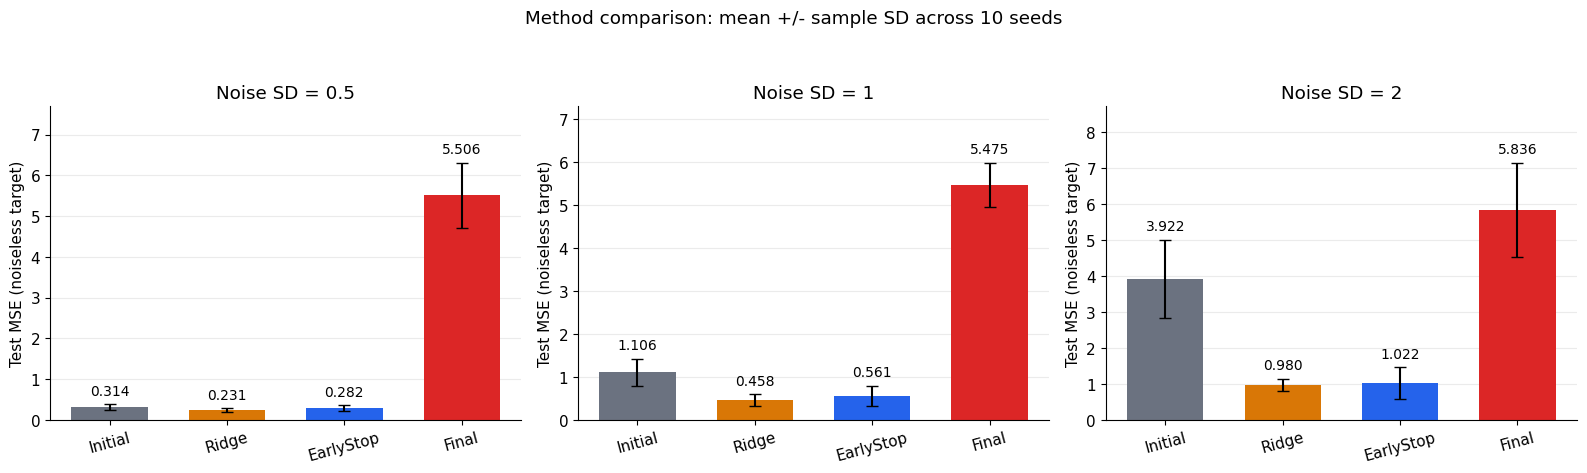

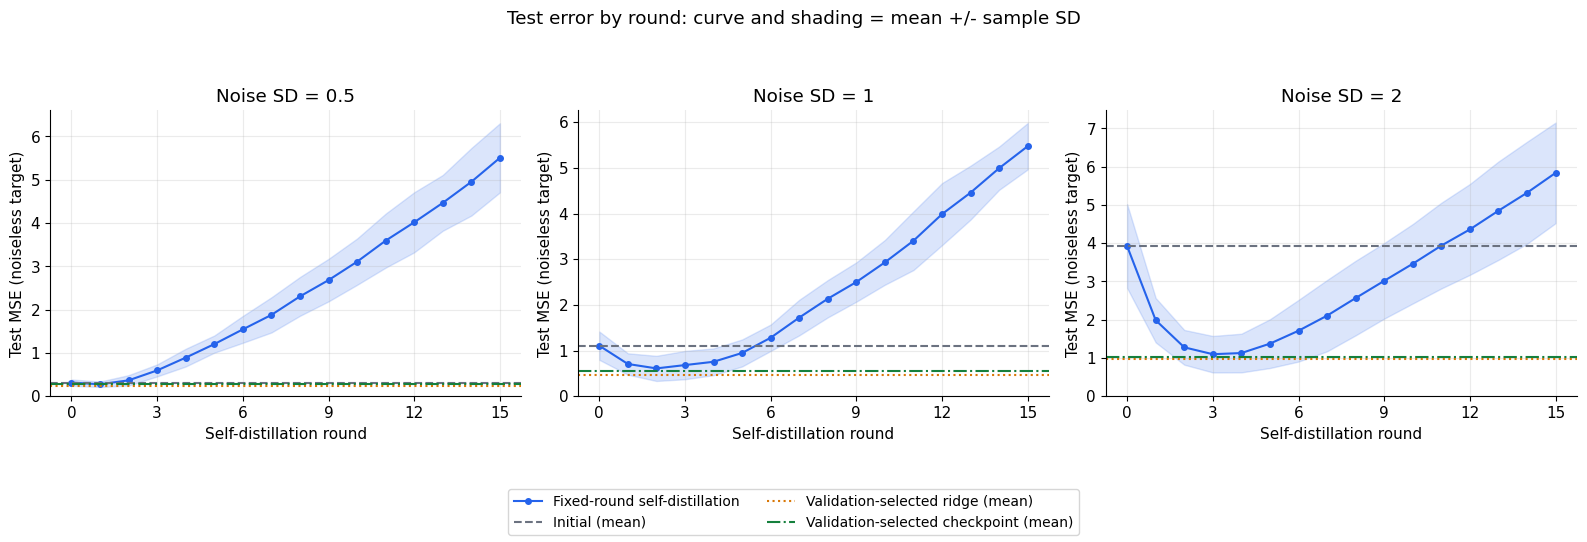

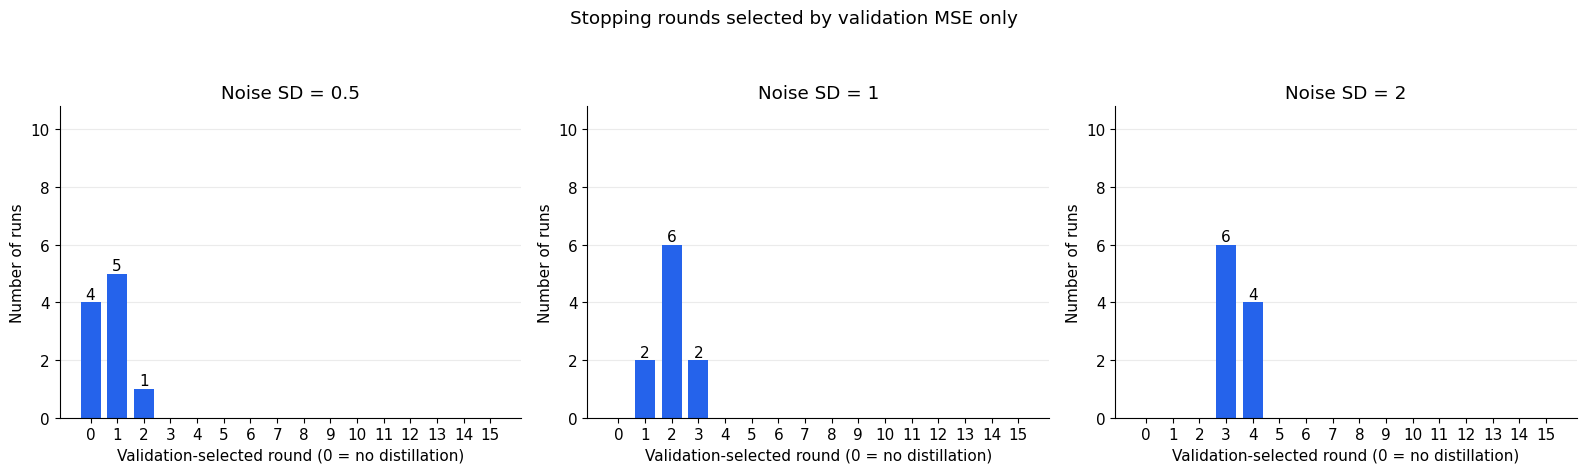

原始记录与汇总均值、样本标准差：核对通过
已生成3张正式实验图片，位置： project_outputs/figures
第九步：正式实验绘图完成


In [47]:
# 出图
import csv
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


# ---------- 读取正式实验结果 ----------
result_dir = Path("project_outputs")

required = [
    "formal_config.json",
    "formal_runs.csv",
    "formal_rounds.csv",
    "formal_summary.csv"
]

missing = [
    name for name in required
    if not (result_dir / name).exists()
]

if missing:
    raise FileNotFoundError(
        "缺少结果文件：" + ", ".join(missing)
        + "。先不要重跑实验，请把报错发给我。"
    )


def read_result_csv(name):
    with (result_dir / name).open(
        "r", encoding="utf-8", newline=""
    ) as f:
        return list(csv.DictReader(f))


cfg = json.loads(
    (result_dir / "formal_config.json").read_text(
        encoding="utf-8"
    )
)

runs = read_result_csv("formal_runs.csv")
rounds = read_result_csv("formal_rounds.csv")
summary = read_result_csv("formal_summary.csv")

noises = cfg["noise_stds"]
seeds = cfg["seeds"]

methods = ["Initial", "Ridge", "EarlyStop", "Final"]
colors = ["#6B7280", "#D97706", "#2563EB", "#DC2626"]

round_numbers = np.arange(cfg["max_rounds"] + 1)


def select_rows(rows, sigma, method=None):
    return [
        row for row in rows
        if float(row["noise_std"]) == sigma
        and (method is None or row["method"] == method)
    ]


summary_lookup = {
    (float(row["noise_std"]), row["method"]): row
    for row in summary
}


# ---------- 绘图前核对数据 ----------
n_trials = len(noises) * len(seeds)

assert len(runs) == n_trials * 4, "方法记录数量不完整"

assert len(rounds) == (
    n_trials * len(round_numbers)
), "逐轮记录数量不完整"

assert (
    len(summary_lookup)
    == len(summary)
    == len(noises) * 4
), "汇总记录不完整或重复"

# 从原始记录重新计算，核对保存的均值与样本标准差
for sigma in noises:
    for method in methods:
        group = select_rows(runs, sigma, method)
        saved = summary_lookup[(sigma, method)]

        assert (
            len(group)
            == len(seeds)
            == int(saved["n_repeats"])
        )

        for metric in ["train_mse", "val_mse", "test_mse"]:
            values = np.array([
                float(r[metric]) for r in group
            ])

            assert (
                np.all(np.isfinite(values))
                and np.all(values >= 0)
            ), "存在无效误差"

            assert np.isclose(
                values.mean(),
                float(saved[metric + "_mean"]),
                rtol=1e-10,
                atol=1e-12
            ), "均值核对失败"

            assert np.isclose(
                values.std(ddof=1),
                float(saved[metric + "_std"]),
                rtol=1e-10,
                atol=1e-12
            ), "标准差核对失败"


# ---------- 图片保存位置与统一格式 ----------
fig_dir = result_dir / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False
})


# ==========================================
# 图1：四种方法的测试误差
# 柱高：10次实验均值
# 误差线：样本标准差，不是置信区间
# ==========================================
fig, axes = plt.subplots(
    1, len(noises),
    figsize=(16, 4.8),
    squeeze=False
)

for ax, sigma in zip(axes[0], noises):
    means = np.array([
        float(summary_lookup[(sigma, m)]["test_mse_mean"])
        for m in methods
    ])

    stds = np.array([
        float(summary_lookup[(sigma, m)]["test_mse_std"])
        for m in methods
    ])

    x = np.arange(len(methods))

    ax.bar(
        x, means,
        yerr=stds,
        color=colors,
        capsize=4,
        width=0.65
    )

    top = float(np.max(means + stds))

    for i, (mu, sd) in enumerate(zip(means, stds)):
        ax.text(
            i,
            mu + sd + 0.025 * top,
            f"{mu:.3f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

    ax.set_xticks(x, methods, rotation=15)
    ax.set_ylim(0, top * 1.22)
    ax.set_title(f"Noise SD = {sigma:g}")
    ax.set_ylabel("Test MSE (noiseless target)")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Method comparison: mean +/- sample SD across 10 seeds"
)

fig.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    fig_dir / "01_test_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================
# 图2：测试误差随蒸馏轮数的变化
# 蓝线：每个固定轮次的平均测试误差
# 蓝色阴影：均值上下一个样本标准差
# 横线：三种对照方法的平均测试误差
# ==========================================
fig, axes = plt.subplots(
    1, len(noises),
    figsize=(16, 5.4),
    squeeze=False
)

for ax, sigma in zip(axes[0], noises):
    lookup = {
        (int(r["seed"]), int(r["round"])): float(r["test_mse"])
        for r in select_rows(rounds, sigma)
    }

    assert len(lookup) == (
        len(seeds) * len(round_numbers)
    ), "逐轮记录不完整或重复"

    matrix = np.array([
        [
            lookup[(seed, int(t))]
            for t in round_numbers
        ]
        for seed in seeds
    ])

    curve_mean = matrix.mean(axis=0)
    curve_std = matrix.std(axis=0, ddof=1)

    ax.plot(
        round_numbers,
        curve_mean,
        "o-",
        color="#2563EB",
        markersize=4,
        label="Fixed-round self-distillation"
    )

    ax.fill_between(
        round_numbers,
        curve_mean - curve_std,
        curve_mean + curve_std,
        color="#2563EB",
        alpha=0.16
    )

    references = [
        (
            "Initial", "#6B7280", "--",
            "Initial (mean)"
        ),
        (
            "Ridge", "#D97706", ":",
            "Validation-selected ridge (mean)"
        ),
        (
            "EarlyStop", "#15803D", "-.",
            "Validation-selected checkpoint (mean)"
        )
    ]

    for method, color, style, label in references:
        value = float(
            summary_lookup[(sigma, method)]["test_mse_mean"]
        )

        ax.axhline(
            value,
            color=color,
            linestyle=style,
            label=label
        )

    ax.set_title(f"Noise SD = {sigma:g}")
    ax.set_xlabel("Self-distillation round")
    ax.set_ylabel("Test MSE (noiseless target)")
    ax.set_xticks([0, 3, 6, 9, 12, 15])
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    fontsize=10
)

fig.suptitle(
    "Test error by round: curve and shading = mean +/- sample SD"
)

fig.tight_layout(rect=[0, 0.15, 1, 0.93])

fig.savefig(
    fig_dir / "02_test_error_by_round.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================
# 图3：验证集选出的停止轮数分布
# 横轴：停止轮数
# 纵轴：10次实验中选中该轮次的次数
# ==========================================
fig, axes = plt.subplots(
    1, len(noises),
    figsize=(16, 4.8),
    squeeze=False
)

for ax, sigma in zip(axes[0], noises):
    selected = [
        int(r["selected_round"])
        for r in select_rows(runs, sigma, "EarlyStop")
    ]

    counts = np.array([
        selected.count(int(t))
        for t in round_numbers
    ])

    assert counts.sum() == len(seeds)

    ax.bar(
        round_numbers,
        counts,
        color="#2563EB",
        width=0.75
    )

    for t, count in zip(round_numbers, counts):
        if count:
            ax.text(
                t,
                count + 0.12,
                str(count),
                ha="center"
            )

    ax.set_title(f"Noise SD = {sigma:g}")
    ax.set_xlabel(
        "Validation-selected round (0 = no distillation)"
    )
    ax.set_ylabel("Number of runs")
    ax.set_xticks(round_numbers)
    ax.set_yticks(range(0, len(seeds) + 1, 2))
    ax.set_ylim(0, len(seeds) + 0.8)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "Stopping rounds selected by validation MSE only"
)

fig.tight_layout(rect=[0, 0, 1, 0.93])

fig.savefig(
    fig_dir / "03_stopping_rounds.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("原始记录与汇总均值、样本标准差：核对通过")
print("已生成3张正式实验图片，位置：", fig_dir)
print("第九步：正式实验绘图完成")

In [48]:
from pathlib import Path
import shutil
from google.colab import files

result_dir = Path("project_outputs")

if not result_dir.is_dir():
    raise FileNotFoundError(
        "没有找到结果文件夹，请先不要重跑，把报错发给我。"
    )

backup_path = shutil.make_archive(
    "ML_Final_Project_results",
    "zip",
    root_dir=str(result_dir)
)

files.download(backup_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>